# 01 · Quantize MANGO1.5-Qwen3.5-9B สำหรับ GreenMind Hackathon

**หน้าที่ของ notebook นี้ = หน้าที่ของคนทำ quantize** สร้าง checkpoint ที่เร็วขึ้นและใช้พลังงานน้อยลงบน A100, พิสูจน์ว่าคุณภาพภาษาไทยยังผ่าน, เก็บผลทุกรอบไว้บน Drive และสร้างชุดส่งมอบ (`HANDOFF.md`) ให้คนทำ serving

**วิธีใช้:** รันจากบนลงล่างทีละ cell และอ่าน "✅ ควรเห็น" ก่อนกด cell ถัดไป **ไม่ต้องแก้ตัวแปรใด ๆ** เพราะแต่ละสูตรมีส่วนของตัวเอง ส่วนละ 3 cell:
1. `lab.quantize(...)` โหลดโมเดล BF16 ใหม่ → ใส่ recipe → quantize → ตารางว่าเลเยอร์ไหนถูก quantize จริง
2. `lab.evaluate(run)` คุณภาพเทียบ BF16 (PPL, top-1 agree) + คำตอบภาษาไทยเทียบกันแบบเคียงข้าง
3. `lab.save(run)` บันทึก + ใส่หัว MTP + push ขึ้น Hub + เพิ่มแถวในตารางเปรียบเทียบ + คืนหน่วยความจำ

**ปรับตาม grader (Participant Briefing):** คะแนน S = 100 · A · s_E^0.6 · s_T^0.2 · s_L^0.2 โดย A (ความแม่นยำเทียบ BF16) คูณทุกอย่าง ถ้าความแม่นยำต่ำกว่า 85% ของ baseline คะแนนแทบเป็นศูนย์ ดังนั้น notebook นี้จึง
1. **calibrate ด้วย trace ที่ MANGO สร้างเอง** (self-calibration, Williams et al. NAACL 2025, arXiv 2410.17170) ครบ 6 ประเภทของ grader: chat, RAG, tool, reasoning, ไทย, long-context โดย**เปิด thinking** เหมือนตอนแข่ง ทำให้ quantizer เห็น activation ของ `<think>` ยาว ๆ และ tool call จริง
2. วัดคุณภาพบน **trace ที่กันไว้ (held-out)** เป็นตัวชี้วัดหลัก (`dppl_trace_%`, `top1_trace_%`)
3. ทำ **W8A8 ก่อน** เพราะเสี่ยงต่อ A น้อยที่สุด แล้วค่อย W4A16

**ลำดับและงบเวลา A100** (ประมาณการ ยังไม่ได้จับเวลาบนโมเดลจริง ระหว่างรันจะเห็นความคืบหน้าทีละเลเยอร์)

| ส่วน | ทำครั้งเดียว / ต่อสูตร | เวลาโดยประมาณ |
|---|---|---|
| Setup + ดาวน์โหลด | ครั้งเดียว | 10–15 นาที |
| 0.7 self-calibration trace (ติดตั้ง vLLM + สร้าง trace) | ครั้งเดียว เก็บบน Drive | 20–35 นาที |
| calibration set + baseline | ครั้งเดียว | 10–15 นาที |
| สูตร 1 `sq-gptq-w8a8` (ตัวหลัก) | ต่อสูตร | 40–70 นาที |
| สูตร 2 `gptq-w4a16` | ต่อสูตร | 40–70 นาที |
| สูตร 3–5 | ทำถ้ามีเวลา | 40–70 นาทีต่อสูตร |
| ตารางเปรียบเทียบ + handoff | ครั้งเดียว | 2 นาที |

ถ้า A100 จำกัด ให้ทำแค่ Setup → สูตร 1 → สูตร 2 → handoff ก็ส่งงานได้แล้ว ถ้า session หลุด ผลที่บันทึกแล้วไม่หาย (อยู่บน Drive และ Hub) ให้รันใหม่ตั้งแต่ขั้น 0.2 แล้วข้ามสูตรที่ทำเสร็จแล้ว

Runtime: **GPU A100 + High-RAM** (ต้องใช้ RAM ≥ 40 GB เพื่อถือโมเดล BF16 บน CPU)

## 0.1 · ติดตั้ง (ครั้งเดียวต่อ runtime)
llm-compressor 0.12.0 ต้องใช้ transformers 5.9–5.10 ซึ่งใหม่กว่าที่ Colab ติดตั้งมา cell นี้จะติดตั้งแล้ว **ปิด session เอง** (เห็นข้อความว่า session crashed ได้ ไม่ต้องตกใจ) จากนั้นรันต่อที่ 0.2

ถ้ากด Runtime → Restart session ทีหลัง ไม่ต้องรันขั้นนี้ซ้ำ แต่ถ้า Disconnect and delete runtime ต้องรันใหม่

In [ ]:
!pip install "llmcompressor==0.12.0" hf_transfer matplotlib
import os; os.kill(os.getpid(), 9)   # รีสตาร์ท session ให้โหลดเวอร์ชันใหม่

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 60.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 169.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 142.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 153.2 MB/s  0:00:00
  Attempting uninstall: nvidia-ml-py
    Found existing installation: nvidia-ml-py 13.615.71
    Uninstalling nvidia-ml-py-13.615.71:
      Successfully uninstalled nvidia-ml-py-13.615.71
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
  Attempting uninstall: transformers
    Found existing installation: transformers 5.20.2
    Uninstalling transformers-5.20.2:
      Successfully uninstalled transformers-5.20.2
  Attempting uninstall: accelerate
    Found existing installation: accelerate 1.15.0
    Uninstalling accelerate-1.15.0:
      Successfully uninstalled accelera

## 0.2 · Drive + toolkit + ล็อกอิน Hugging Face
ใช้ `HF_TOKEN` จาก 🔑 Secrets ของ Colab (ต้องเป็น token สิทธิ์ **write**) ชื่อผู้ใช้จะอ่านจาก token อัตโนมัติ ไม่ต้องพิมพ์เอง

✅ ควรเห็น: `ล็อกอิน Hugging Face เป็น <ชื่อของคุณ>` และ `toolkit พร้อม`

In [ ]:
from google.colab import drive, userdata
drive.mount('/content/drive')

import os, sys, shutil, zipfile
ZIP = '/content/drive/MyDrive/greenmind/greenmind-quant.zip'
for d in ('/content/gm', '/content/greenmind-quant'):
    shutil.rmtree(d, ignore_errors=True)
with zipfile.ZipFile(ZIP) as z:
    z.extractall('/content')
shutil.move('/content/greenmind-quant', '/content/gm')
sys.path.insert(0, '/content/gm')

os.environ.update(
    HF_TOKEN=userdata.get('HF_TOKEN'),
    HF_HOME='/content/hf_cache',                  # ดิสก์ในเครื่อง เร็วกว่า Drive
    HF_HUB_ENABLE_HF_TRANSFER='1',
    GM_RESULTS_DIR='/content/drive/MyDrive/greenmind/results',
    TOKENIZERS_PARALLELISM='false',
    PYTHONPATH='/content/gm',                     # ให้ subprocess (เช่น gm.handoff) หาโมดูลเจอ
)

from huggingface_hub import HfApi
me = HfApi().whoami()                             # อ่านจาก HF_TOKEN
HF_USER = me['name']
print('ล็อกอิน Hugging Face เป็น', HF_USER)
print('toolkit พร้อม:', sorted(os.listdir('/content/gm/gm')))

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


ล็อกอิน Hugging Face เป็น Nattapon248
toolkit พร้อม: ['__init__.py', 'bench_energy.py', 'calib_data.py', 'calib_trace.py', 'common.py', 'eval_ppl.py', 'eval_tasks.py', 'explore.py', 'handoff.py', 'lab.py', 'loadtest.py', 'mtp_splice.py', 'quantize.py', 'recipes.py', 'select_best.py', 'texts.py', 'workload.py']


## 0.3 · ตรวจเวอร์ชันและฮาร์ดแวร์
✅ ควรเห็น: llmcompressor 0.12.0, transformers 5.9.x หรือ 5.10.x, `CUDA ใช้ได้: True`, GPU เป็น A100 และ RAM ≥ 40 GiB

❌ transformers ยังเป็น 4.x → ยังไม่ได้รีสตาร์ทหลัง 0.1 ให้กด Runtime → Restart session แล้วรัน 0.2 ใหม่
❌ `CUDA ใช้ได้: False` บน runtime ที่เป็น GPU → torch ที่ pip ติดตั้งมาไม่ตรงกับ driver ของ Colab ให้ส่งบรรทัด `torch CUDA` และ `driver` มาให้ผมดู

In [ ]:
import gc, json, os, sys, time, pathlib, subprocess
import torch, transformers, llmcompressor, compressed_tensors
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from gm import explore as ex
from gm.common import RESULTS_DIR, package_versions

print(package_versions('llmcompressor', 'compressed-tensors', 'transformers', 'torch', 'datasets'))
assert transformers.__version__.startswith('5.'), 'transformers ยังเป็นเวอร์ชันเก่า: รีสตาร์ท session แล้วรัน 0.2 ใหม่'
print('CUDA ใช้ได้:', torch.cuda.is_available(), '| torch CUDA', torch.version.cuda)
try:
    print('driver:', subprocess.run(['nvidia-smi', '--query-gpu=name,driver_version,memory.total',
                                     '--format=csv,noheader'], capture_output=True, text=True).stdout.strip())
except FileNotFoundError:
    print('driver: ไม่พบ nvidia-smi (ไม่ได้อยู่บน GPU runtime)')
ram = int(open('/proc/meminfo').readline().split()[1]) / 2**20
print(f'RAM: {ram:.0f} GiB')

{'llmcompressor': '0.12.0', 'compressed-tensors': '0.17.1', 'transformers': '5.10.1', 'torch': '2.11.0+cu130', 'datasets': '4.8.5'}
CUDA ใช้ได้: True | torch CUDA 13.0
driver: NVIDIA A100-SXM4-80GB, 580.82.07, 81920 MiB
RAM: 167 GiB


## 0.4 · ค่าที่ใช้กับทุกสูตร (ไม่ต้องแก้)
- **384 samples × 4096 tokens**: ยาวกว่าที่ CMKL ใช้ (512 × 2048) เพราะคำตอบแบบ thinking ใน grader ยาวหลายพัน token ถ้า calibrate แค่ 2048 token quantizer จะไม่เคยเห็น activation ช่วงท้ายของการคิด รวมราว 1–1.5 ล้าน token ซึ่งเกิน d_in ของเลเยอร์ใหญ่สุด (12,288) หลายสิบเท่า GPTQ จึงไม่ overfit
- ในนั้น **320 ตัวอย่างเป็น self-calibration trace** (ขั้น 0.7) อีก 64 ตัวอย่างเป็นแชทสาธารณะไทย/อังกฤษ เพื่อกันไม่ให้แคบเกินไป
- ทุกสูตรใช้ calibration set ชุดเดียวกัน ผลจึงเทียบกันได้ตรง ๆ
- `PUSH = True`: push checkpoint ขึ้น Hub เป็น repo **private** ชื่อ `<HF_USER>/mango15-<สูตร>` เพื่อให้ serving ดึงไปใช้ได้

ถ้า A100 เหลือน้อยมากจริง ๆ ให้ลด `NUM_SAMPLES = 256` ซึ่งจะเร็วขึ้นราวหนึ่งในสาม แลกกับคุณภาพที่อาจลดลงเล็กน้อย

In [ ]:
SOURCE = 'CMKL/MANGO1.5-Qwen3.5-9B'
NUM_SAMPLES, SEQ_LEN = 384, 4096
TRACE_N, TRACE_HOLDOUT = 320, 24          # self-calibration traces (0.7) + held-out traces for evaluation
PUSH = True
HF_USER = globals().get('HF_USER')        # มาจาก 0.2
print(f'source={SOURCE} · calibration={NUM_SAMPLES}×{SEQ_LEN} · push={PUSH and bool(HF_USER)} as {HF_USER}')
print('ผลลัพธ์จะถูกเก็บที่', RESULTS_DIR)

source=CMKL/MANGO1.5-Qwen3.5-9B · calibration=384×4096 · push=True as Nattapon248
ผลลัพธ์จะถูกเก็บที่ /content/drive/MyDrive/greenmind/results


## 0.5 · ดาวน์โหลดโมเดล
เก็บไว้ที่ `/content/hf_cache` ถ้า session นี้เคยโหลดแล้วจะเสร็จทันที

✅ ควรเห็น: progress bar ของไฟล์ `.safetensors` แล้วตามด้วยตารางไฟล์ รวมราว 19 GB และมีไฟล์ที่ชื่อมี `mtp` (หัว MTP)

In [ ]:
from huggingface_hub import snapshot_download
t = time.time()
SRC_DIR = SOURCE if pathlib.Path(SOURCE).exists() else snapshot_download(SOURCE)
files = sorted(pathlib.Path(SRC_DIR).glob('*.safetensors'))
display(pd.DataFrame([{'file': f.name, 'GB': round(f.stat().st_size / 1e9, 2)} for f in files]))
print(f'รวม {sum(f.stat().st_size for f in files) / 1e9:.1f} GB · {(time.time() - t) / 60:.1f} นาที')

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

,file,GB
0,model-00001-of-00005.safetensors,4.91
1,model-00002-of-00005.safetensors,4.95
2,model-00003-of-00005.safetensors,4.99
3,model-00004-of-00005.safetensors,3.97
4,model-00005-of-00005.safetensors,0.49


รวม 19.3 GB · 0.9 นาที


## 0.6 · Tokenizer และ chat template
calibration data ต้องหน้าตาเหมือนแชทจริง cell นี้แสดงข้อความที่โมเดลเห็นจริงหลังผ่าน chat template

✅ ควรเห็น: system prompt ของ Mango, แท็ก `<|im_start|>user` และจำนวน token ของประโยคไทยเทียบกับอังกฤษ

In [ ]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained(SRC_DIR)
msgs = [{'role': 'user', 'content': 'สวัสดีครับ ช่วยสรุปข่าววันนี้ให้หน่อย'}]
print(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=False))
th = 'การ quantize ทำให้โมเดลเล็กลงและสร้างคำตอบได้เร็วขึ้น'
en = 'Quantization makes the model smaller and lets it generate answers faster'
print(f"ไทย {len(tok(th)['input_ids'])} tokens · อังกฤษ {len(tok(en)['input_ids'])} tokens")

<|im_start|>user
สวัสดีครับ ช่วยสรุปข่าววันนี้ให้หน่อย<|im_end|>
<|im_start|>assistant
<think>

</think>


ไทย 24 tokens · อังกฤษ 12 tokens


## 0.7a · Self-calibration: ให้ MANGO BF16 สร้าง trace แบบเดียวกับ grader (ครั้งเดียว เก็บบน Drive)
**หลักการ:** quantizer (GPTQ/SmoothQuant) ปรับ weight ให้ output ผิดน้อยที่สุด *บน activation ที่มันเห็น* ถ้า calibration ไม่เหมือนงานจริง มันจะไปรักษาส่วนที่ไม่สำคัญ งานของ Williams et al. (NAACL 2025) พบว่าข้อความที่โมเดลสร้างเองใช้ calibrate ได้ดีเท่าหรือดีกว่าข้อมูลจริง เพราะตรงกับ distribution ของโมเดลเอง

cell นี้
1. ติดตั้ง vLLM ใน venv แยก (`/content/venvs/serve`) ไม่ชนกับ llm-compressor
2. สร้าง prompt แบบเดียวกับ grader 6 ประเภท (chat, RAG, tool calling พร้อม tools, reasoning, ไทย, long-context) จากข้อมูลเปิด (UltraChat, Wikipedia shard แรก, GSM8K/MBPP, WangchanThaiInstruct) **ไม่มีข้อสอบของ grader** ตามกติกา
3. ให้ MANGO BF16 ตอบด้วย **thinking เปิด, temperature 0** แล้วเก็บ prompt + คำตอบเป็น calibration 320 ตัวอย่าง + กันไว้วัดผล 24 ตัวอย่าง
4. ทดสอบเพิ่ม 24 คำถามที่ max_tokens 8192 เพื่อดูว่า BF16 คิดยาวเท่าไรและโดนตัดที่ 8192 บ่อยไหม (ข้อมูลสำคัญให้ serving)

✅ ควรเห็น: log ติดตั้ง → `generated 344 traces in N min` → ตารางสถิติต่อประเภท (`gen_tokens` เฉลี่ย, `finish`) และ `bf16_full_length_probe`
❌ ถ้าล้มเหลว (เช่น ติดตั้ง vLLM ไม่ได้) cell จะบอกและ **ใช้ calibration สาธารณะแทนอัตโนมัติ** ยังรันต่อได้ แต่ส่งข้อความ error ให้ผมดู

In [ ]:
from gm.common import run_live
TRACE = RESULTS_DIR / 'quantization' / 'self_calib_trace.jsonl'
SERVE_PY = '/content/venvs/serve/bin/python'
if TRACE.exists():
    print('ใช้ trace เดิมบน Drive:', TRACE)
else:
    try:
        if not pathlib.Path(SERVE_PY).exists():
            run_live(['bash', '/content/gm/setup_envs.sh', 'serve'])
        rc = run_live([SERVE_PY, '-m', 'gm.calib_trace', '--model', SRC_DIR, '--out', str(TRACE),
                       '--n', str(TRACE_N), '--holdout', str(TRACE_HOLDOUT), '--seq-cap', str(SEQ_LEN)])
        if rc != 0 or not TRACE.exists():
            raise RuntimeError(f'calib_trace exit code {rc}')
    except Exception as e:
        print('⚠️ self-calibration ล้มเหลว:', e, '→ ใช้ calibration สาธารณะแทน')
        TRACE = None
if TRACE:
    st = json.loads(TRACE.with_suffix('.stats.json').read_text())
    print('calibration traces ต่อประเภท:'); display(pd.DataFrame(st['calibration']).T)
    if 'bf16_full_length_probe' in st:
        print('BF16 ที่ max_tokens 8192 (finished_% ต่ำ = คิดยาวจนโดนตัด → แจ้ง serving):')
        display(pd.DataFrame(st['bf16_full_length_probe']).T)

$ bash /content/gm/setup_envs.sh serve
serve env OK | vllm 0.27.1 | torch 2.13.0+cu130 | cuda True

[exit code 0 · 0.9 min]
$ /content/venvs/serve/bin/python -m gm.calib_trace --model /content/hf_cache/hub/models--CMKL--MANGO1.5-Qwen3.5-9B/snapshots/c0e66f0d0de2d747d1b7d7e27c94f82de9d4f920 --out /content/drive/MyDrive/greenmind/results/quantization/self_calib_trace.jsonl --n 320 --holdout 24 --seq-cap 4096
/content/venvs/serve/lib/python3.12/site-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
15:04:02 | INFO    | texts | Wikipedia en: first shard 20231101.en/train-00000-of-00041.parquet (of 41)
15:04:04 | INFO    | workload | Wikipedia en/

## 0.7b · ประกอบ calibration set (ใช้กับทุกสูตร)
trace 320 ตัวอย่างจาก 0.7a + แชทสาธารณะ 64 ตัวอย่าง (ไทย 35% จาก WangchanThaiInstruct, อังกฤษ 65% จาก UltraChat) ตัดที่ 4096 tokens trace ที่กันไว้ 24 ตัวอย่าง (`split = eval`) **ไม่ถูกใช้ calibrate** แต่ใช้วัดผลใน `lab.evaluate`

✅ ควรเห็น: `loaded 320 user calibration rows`, สถิติความยาวเฉลี่ยหลายพัน token และตัวอย่างที่มี `<think>` กับ `<tool_call>` อยู่ในข้อความ
❌ ถ้า `thai_samples_%` ใกล้ 0 แปลว่าโหลดข้อมูลไทยไม่ได้ (ดู warning ด้านบน) **อย่ารันต่อ** เพราะคุณภาพภาษาไทยจะเสีย

In [ ]:
from gm.calib_data import build_calibration_dataset
t = time.time()
calib_ds = build_calibration_dataset(tok, NUM_SAMPLES, SEQ_LEN, thai_ratio=0.35, seed=42,
                                     calib_jsonl=str(TRACE) if TRACE else None)
calib_stats = ex.describe_calibration(calib_ds, tok)
CALIB_TAG = f"{'self-trace' if TRACE else 'public'} {NUM_SAMPLES}x{SEQ_LEN}"
print(f'\n{CALIB_TAG} · {(time.time() - t) / 60:.1f} นาที')

calib WangchanThaiInstruct:   0%|          | 0/134 [00:00<?, ?sample/s]

15:08:26 | INFO    | calib | took 134 samples so far (after airesearch/WangchanThaiInstruct)


calib ultrachat_200k:   0%|          | 0/250 [00:00<?, ?sample/s]

15:08:30 | INFO    | calib | took 250 samples so far (after HuggingFaceH4/ultrachat_200k)
15:08:32 | INFO    | calib | calibration set: 384 samples, mean 1277 tokens, max 4096
สถิติ calibration: {'samples': 384, 'thai_samples_%': 34.9, 'tokens_total': 490517, 'tokens_mean': 1277, 'tokens_max': 4096}

--- ตัวอย่างภาษาไทย (#0, 999 tokens) ---
<|im_start|>user
ตราพระราชบัญญัติว่าด้วยระเบียบการบริหารแห่งราชอาณาจักรสยาม พ.ศ. ๒๔๗๖ ลงวันที่ ๙ ธันวาคม พ.ศ. ๒๔๗๖ กำหนดระเบียบราชการบริหารส่วนภูมิภาคแบ่งเป็นจังหวัดและอำเภอ ยกเลิกการปกครองแบบมณฑล  ใช่หรือไม่<|im_end|>
<|im_start|>assistant
<think>

</think>

ใช่ ตราพระราชบัญญัติว่าด้วยระเบียบการบริหารแห่งราชอาณาจักรสยาม พ.ศ. ๒๔๗๖ ลงวันที่ ๙ ธันวาค…

--- ตัวอย่างภาษาอังกฤษ (#1, 2574 tokens) ---
<|im_start|>user
Please develop a PowerShell script that includes functionality to automate the backup process of files and directories to a remote server. The script should be able to:<|im_end|>
<|im_start|>assistant
1. Prompt the user for the file or direct

## 0.8 · โหลดโมเดล BF16 และดูโครงสร้าง
โหลดบน CPU เพราะ llm-compressor จะย้ายเลเยอร์ขึ้น GPU ทีละชั้นตอน quantize

✅ ควรเห็น: `layer_types` เป็น linear_attention 24 กับ full_attention 8 และตารางกลุ่มเลเยอร์ที่ MLP มีพารามิเตอร์มากที่สุด คอลัมน์ `plan` บอกว่ากลุ่มไหนจะถูก quantize ส่วนที่คงเป็น BF16 (`lm_head`, embedding, vision) คือเหตุที่ INT4 ไม่เล็กลงถึง 4 เท่า

In [ ]:
from gm.lab import QuantLab
lab = QuantLab(SRC_DIR, SOURCE, tok, calib_ds, calib_stats, RESULTS_DIR,
               hf_user=HF_USER if PUSH else None, seq_len=SEQ_LEN,
               trace_path=TRACE)
inventory = lab.inventory()

[ERROR] `loss` is part of Qwen3_5CausalLMOutputWithPast.__init__'s signature, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen3_5/modeling_qwen3_5.py.
[ERROR] `logits` is part of Qwen3_5CausalLMOutputWithPast.__init__'s signature, but not documented. Make sure to add it to the docstring of the function in /usr/local/lib/python3.13/dist-packages/transformers/models/qwen3_5/modeling_qwen3_5.py.


[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

โหลด BF16 บน CPU เสร็จ 0.0 นาที
layer_types: {'linear_attention': 24, 'full_attention': 8}


,group,layers,params_M,bf16_GB,plan,share_%
0,mlp (gate/up/down),96,4831.8,9.66,quantize,51.4
1,gdn_proj (qkv/z/out),72,1610.6,3.22,quantize,17.1
2,lm_head,1,1017.1,2.03,BF16 (อ่อนไหวมาก กระทบทุก token),10.8
3,embed_tokens,1,1017.1,2.03,BF16 (ไม่ใช่ Linear),10.8
4,full_attn (q/k/v/o),32,469.8,0.94,quantize,5.0
5,vision,110,451.2,0.90,BF16 (ไม่ได้ใช้ (MANGO1.5 เป็น text-only)),4.8
6,gdn_gate (in_proj_a/b),48,6.3,0.01,BF16 (เล็กมาก แต่ error สะสมใน recurrent state),0.1


ส่วนที่จะ quantize: 6.91B params (74% ของโมเดล)


## 0.9 · BF16 baseline (คำนวณครั้งแรกครั้งเดียว เก็บบน Drive)
วัดโมเดลต้นฉบับไว้เป็นตัวเทียบของทุกสูตร
- PPL และ top-1 บน **trace ที่กันไว้** (ตัวชี้วัดหลัก เพราะเหมือนงานใน grader ที่สุด) + PPL ไทยและอังกฤษ (Wikipedia shard สุดท้าย / WikiText)
- คำตอบตัวอย่าง 3 ข้อ
- activation จริงที่ไหลเข้า `layers.15.mlp.down_proj` เพื่อใช้ใน 0.10 และในการตรวจรายเลเยอร์ของแต่ละสูตร

✅ ควรเห็น: ตาราง PPL (ไทยมักสูงกว่าอังกฤษ เป็นเรื่องปกติ) และคำตอบภาษาไทยที่อ่านรู้เรื่อง

In [ ]:
base = lab.baseline()

ใช้ baseline เดิมจาก /content/drive/MyDrive/greenmind/results/quantization/bf16_baseline.pt


,model,PPL th,PPL en
0,bf16,7.276,11.452


,prompt,BF16 answer
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...


## 0.10 · ห้องทดลอง: ปัดเลขตรง ๆ (RTN) แบบต่าง ๆ บนเลเยอร์จริง
ใช้เวลาไม่กี่วินาที และเป็นเส้นฐานให้รู้ว่า GPTQ / AWQ / SmoothQuant ช่วยได้เท่าไร
- **weight err**: weight เปลี่ยนไปเท่าไร
- **output err**: ผลคูณกับ activation จริงเปลี่ยนไปเท่าไร ซึ่งเลเยอร์ถัดไปรับรู้จริง **ตัวนี้สำคัญกว่า**

✅ ควรเห็นแนวโน้มนี้: W8 error น้อยมาก · W4 per-channel สูง · W4 g128 ลดลงชัดเจน (เหตุที่ทุกคนใช้ group 128) · g32 ดีขึ้นอีกแต่ไฟล์ใหญ่ขึ้น · W3 พุ่งขึ้น

,scheme (RTN),bits/weight,size vs BF16,weight err %,output err %
0,W8 per-channel sym,8.000,50%,1.09,1.03
1,W4 per-channel sym,4.000,25%,19.72,18.67
2,W4 g128 sym,4.125,26%,12.31,11.65
3,W4 g128 asym,4.156,26%,10.42,9.86
4,W4 g32 sym,4.500,28%,9.99,9.46
5,W3 g128 sym,3.125,20%,28.70,26.99


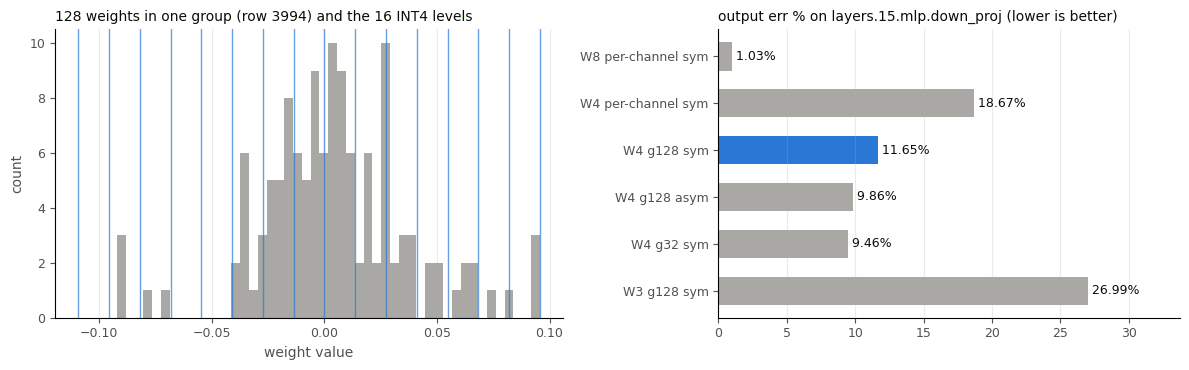

In [ ]:
rtn = lab.rtn_lab()

## สูตร 1 · `sq-gptq-w8a8` — ตัวหลักสำหรับ grader
**SmoothQuant (α 0.8) แล้วตามด้วย GPTQ, INT8 weight + INT8 activation แบบ dynamic per-token** — ใน grader คะแนนทั้งหมดถูกคูณด้วย A (ความแม่นยำเทียบ BF16) ถ้า A ตก ทุกอย่างพัง งานวิจัย *Quantization Hurts Reasoning?* (arXiv 2504.04823) พบว่า W8A8 แทบไม่ทำให้ reasoning model เสีย ขณะที่ 4-bit เริ่มเสียกับโจทย์ยาก และ W8A8 ใช้ INT8 tensor core ของ A100 จึงช่วย prefill ของ RAG / long-context (TTFT) ตอน peak 4 req/s

**cell 1 quantize:** จะเห็น log `Quantizing model.language_model.layers.N…` ไล่ N จาก 0 ถึง 31 (ใช้ดูความคืบหน้า) และ `GPTQ | METRIC - error` ต่อเลเยอร์ ถ้าเป็น `nan` หรือ `inf` ให้หยุด จบแล้วจะเห็นตารางว่าเลเยอร์ไหนถูก quantize จริง และการเทียบกับการปัดตรง ๆ บนเลเยอร์ 15
**cell 2 evaluate:** ตาราง PPL / Δ PPL % / top-1 agree เทียบ BF16 และคำตอบเคียงข้างกัน
**cell 3 save:** บันทึก, ใส่หัว MTP, push และเพิ่มแถวในตารางเปรียบเทียบ

✅ ควรเห็น: Δ PPL-trace ต่ำมาก (ใกล้ 0) · top-1 trace ≥ 97% · quant summary ต้องมี activations เป็น `INT8 dynamic` · ขนาดราว 11–12 GB

In [ ]:
run1 = lab.quantize('sq-gptq-w8a8', notes=f'sq-gptq-w8a8 · {CALIB_TAG}')

▶ sq-gptq-w8a8: recipe
    SmoothQuantModifier(smoothing_strength=0.8, mappings=3 กลุ่ม)
    GPTQModifier(scheme=W8A8, targets=['Linear'], block_size=128, dampening_frac=0.01, actorder=static)
2026-10-24T04:31:59.1391 | reset | INFO - Compression lifecycle reset
2026-10-24T04:31:59.1739 | norm_calibration_context | INFO - Found 81 offset-norm modules to convert
2026-10-24T04:31:59.1820 | from_modifiers | INFO - Creating recipe from modifiers
2026-10-24T04:31:59.2717 | initialize | INFO - Compression lifecycle initialized for 2 modifiers
2026-10-24T04:31:59.2726 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `SmoothQuantModifier`


W1024 04:31:59.854000 4807 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


2026-10-24T04:31:59.9384 | trace_subgraphs | WARNING - Expected 59 subgraphs, but only traced 33. This is likely due to having wrapped code which calls sequential targets


(2/33): Calibrating: 100%|██████████| 384/384 [00:07<00:00, 50.36it/s]

2026-10-24T04:32:14.0836 | _apply_smoothing | INFO - Smoothing with model.language_model.layers.0.post_attention_layernorm


...

(33/33): Propagating: 100%|██████████| 384/384 [00:01<00:00, 235.64it/s]


2026-10-24T05:03:28.8323 | norm_calibration_context | INFO - Restoring 81 norm modules to offset convention
2026-10-24T05:03:28.8897 | finalize | INFO - Compression lifecycle finalized for 2 modifiers
2026-10-24T05:03:28.8903 | post_process | WARNING - Optimized model is not saved. To save, please provide `output_dir` as input arg.Ex. `oneshot(..., output_dir=...)`

✅ quantize เสร็จ 31.5 นาที

เลเยอร์ที่ถูก quantize จริง:


,group,weights,granularity,sym,activations,layers
0,gdn_gate (in_proj_a/b),BF16,-,-,-,48
1,lm_head,BF16,-,-,-,1
2,vision,BF16,-,-,-,110
3,full_attn (q/k/v/o),INT8,channel,sym,INT8 dynamic,32
4,gdn_proj (qkv/z/out),INT8,channel,sym,INT8 dynamic,72
5,mlp (gate/up/down),INT8,channel,sym,INT8 dynamic,96



เลเยอร์ layers.15.mlp.down_proj: การปัดตรง ๆ เทียบกับผลจริง


,method,output err %,weight err %
0,RTN W8 per-channel sym (ปัดตรง ๆ),1.032,1.09
1,sq-gptq-w8a8 (llm-compressor จริง),0.901,1.26


In [ ]:
lab.evaluate(run1)

,model,PPL th,PPL en,Δ PPL th %,top-1 agree th %,Δ PPL en %,top-1 agree en %
0,bf16,7.276,11.452,NaN,NaN,NaN,NaN
1,sq-gptq-w8a8,7.414,11.622,1.9,90.4,1.49,92.8


,prompt,BF16,quantized
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...,ในการแก้สมการ 3x + 7 = 22 เราต้องแยกตัวแปร x อ...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...,Weight-only INT4 quantization speeds up LLM de...


{'th': {'ppl': 7.41444149113153,
  'tokens': 4088,
  'nll': tensor([2.1923e-01, 3.1120e+00, 4.1162e-03,  ..., 3.0662e-03, 2.5401e-01,
          6.2312e+00]),
  'top1': tensor([148438,  34947, 148433,  ...,  19571,  64020,  35982]),
  'top1_agree_%': 90.41095972061157,
  'mean_abs_dnll': 0.15551306307315826,
  'ppl_delta_%': 1.9025349784212553},
 'en': {'ppl': 11.621748771309496,
  'tokens': 4088,
  'nll': tensor([12.3078, 11.4286,  1.1894,  ...,  0.5015,  1.3779,  3.0650]),
  'top1': tensor([  220,   458,   455,  ...,   314,   279, 30223]),
  'top1_agree_%': 92.83267855644226,
  'mean_abs_dnll': 0.1369459182024002,
  'ppl_delta_%': 1.4866822769148635}}

In [ ]:
lab.save(run1, push=PUSH)

05:07:04 | INFO    | quantize | saving compressed checkpoint to /content/models/mango15-sq-gptq-w8a8 ...


Compressing model: 100%|██████████| 200/200 [00:00<00:00, 1054.67it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3470: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Dispatching model: 100%|██████████| 817/817 [00:00<00:00, 19113.94it/s]


05:07:38 | INFO    | mtp | spliced 15 MTP tensors (464.0 MB) into /content/models/mango15-sq-gptq-w8a8
05:07:38 | INFO    | quantize | saved: /content/models/mango15-sq-gptq-w8a8 (12.40 GB, MTP tensors 15)
05:07:38 | INFO    | quantize | uploading to https://huggingface.co/Nattapon248/mango15-sq-gptq-w8a8 (private) ...
05:09:25 | INFO    | quantize | logged run sq-gptq-w8a8@20261024-050738 -> /content/drive/MyDrive/greenmind/results/quantization
✅ MTP tensors: 15 · ขนาด 12.397 GB · /content/models/mango15-sq-gptq-w8a8
Hub: https://huggingface.co/Nattapon248/mango15-sq-gptq-w8a8 (private)
2026-10-24T05:09:25.5179 | reset | INFO - Compression lifecycle reset


,run_id,variant,samples,seq_len,quant_min,size_gb,mtp,dppl_trace_%,top1_trace_%,ppl_th,dppl_th_%,top1_th_%,ppl_en,dppl_en_%,top1_en_%,probe_out_err_%,probe_rtn_err_%,hub,notes
0,sq-gptq-w8a8@20261024-050738,sq-gptq-w8a8,384,4096,31.5,12.397,15,None,None,7.414,1.903,90.411,11.622,1.487,92.833,0.901,1.032,Nattapon248/mango15-sq-gptq-w8a8,sq-gptq-w8a8 · public 384x4096


{'variant': 'sq-gptq-w8a8',
 'source_model': '/content/hf_cache/hub/models--CMKL--MANGO1.5-Qwen3.5-9B/snapshots/c0e66f0d0de2d747d1b7d7e27c94f82de9d4f920',
 'recipe': ["SmoothQuantModifier(index=None, group=None, start=None, end=None, update=None, initialized_=True, finalized_=True, started_=True, ended_=True, smoothing_strength=0.8, mappings=[[['re:.*mlp\\\\.gate_proj$', 're:.*mlp\\\\.up_proj$'], 're:.*post_attention_layernorm$'], [['re:.*layers\\\\.(3|7|11|15|19|23|27|31)\\\\.self_attn\\\\.q_proj$', 're:.*layers\\\\.(3|7|11|15|19|23|27|31)\\\\.self_attn\\\\.k_proj$', 're:.*layers\\\\.(3|7|11|15|19|23|27|31)\\\\.self_attn\\\\.v_proj$'], 're:.*layers\\\\.(3|7|11|15|19|23|27|31)\\\\.input_layernorm$'], [['re:.*layers\\\\.(0|1|2|4|5|6|8|9|10|12|13|14|16|17|18|20|21|22|24|25|26|28|29|30)\\\\.linear_attn\\\\.in_proj_qkv$', 're:.*layers\\\\.(0|1|2|4|5|6|8|9|10|12|13|14|16|17|18|20|21|22|24|25|26|28|29|30)\\\\.linear_attn\\\\.in_proj_z$', 're:.*layers\\\\.(0|1|2|4|5|6|8|9|10|12|13|14|16|17|18

## สูตร 2 · `gptq-w4a16` — ตัวเลือกประหยัดพลังงานสูงสุด
**GPTQ, INT4 weight, group 128, symmetric** — weight เล็กที่สุดที่ Marlin รองรับ decode (memory-bound) จึงเร็วสุดและเหลือหน่วยความจำให้ KV cache มากสุด แต่เสี่ยงกับ reasoning ยาว ๆ ใช้เมื่อคุณภาพผ่านเกณฑ์เท่านั้น

**cell 1 quantize:** จะเห็น log `Quantizing model.language_model.layers.N…` ไล่ N จาก 0 ถึง 31 (ใช้ดูความคืบหน้า) และ `GPTQ | METRIC - error` ต่อเลเยอร์ ถ้าเป็น `nan` หรือ `inf` ให้หยุด จบแล้วจะเห็นตารางว่าเลเยอร์ไหนถูก quantize จริง และการเทียบกับการปัดตรง ๆ บนเลเยอร์ 15
**cell 2 evaluate:** ตาราง PPL / Δ PPL % / top-1 agree เทียบ BF16 และคำตอบเคียงข้างกัน
**cell 3 save:** บันทึก, ใส่หัว MTP, push และเพิ่มแถวในตารางเปรียบเทียบ

✅ ควรเห็น: Δ PPL-trace ไม่เกินราว 3–5% · top-1 trace ≥ 93% · คำตอบภาษาไทยยังอ่านรู้เรื่อง · ขนาดราว 8 GB · MTP 15 tensors

In [ ]:
run2 = lab.quantize('gptq-w4a16', notes=f'gptq-w4a16 · {CALIB_TAG}')

Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

โหลด BF16 บน CPU เสร็จ 0.0 นาที
▶ gptq-w4a16: recipe
    GPTQModifier(scheme=W4A16, targets=['Linear'], block_size=128, dampening_frac=0.01, actorder=static)
2026-10-24T05:09:26.7651 | reset | INFO - Compression lifecycle reset
2026-10-24T05:09:26.7728 | norm_calibration_context | INFO - Found 81 offset-norm modules to convert
2026-10-24T05:09:26.7807 | from_modifiers | INFO - Creating recipe from modifiers
2026-10-24T05:09:26.8380 | initialize | INFO - Compression lifecycle initialized for 1 modifiers
2026-10-24T05:09:26.8387 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `GPTQModifier`
2026-10-24T05:09:27.5233 | trace_subgraphs | WARNING - Expected 59 subgraphs, but only traced 33. This is likely due to having wrapped code which calls sequential targets


(2/33): Calibrating: 100%|██████████| 384/384 [00:17<00:00, 22.18it/s]

2026-10-24T05:09:48.7955 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_qkv using 384 samples


2026-10-24T05:09:51.5200 | GPTQ | METRIC - time 2.72s
2026-10-24T05:09:51.5208 | GPTQ | METRIC - error 54873.32
2026-10-24T05:09:51.5219 | GPTQ | METRIC - Accelerator 0 | usage: 23.48% | total memory: 85.1 Gb
2026-10-24T05:09:51.5985 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_z using 384 samples
2026-10-24T05:09:54.2445 | GPTQ | METRIC - time 2.65s
2026-10-24T05:09:54.2453 | GPTQ | METRIC - error 27406.17
2026-10-24T05:09:54.2464 | GPTQ | METRIC - Accelerator 0 | usage: 23.48% | total memory: 85.1 Gb
2026-10-24T05:09:54.2837 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.out_proj using 384 samples
2026-10-24T05:09:56.9254 | GPTQ | METRIC - time 2.64s
2026-10-24T05:09:56.9262 | GPTQ | METRIC - error 12.43
2026-10-24T05:09:56.9272 | GPTQ | METRIC - Accelerator 0 | usage: 23.48% | total memory: 85.1 Gb
2026-10-24T05:09:56.9655 | compress_module_list | INFO - Quantizing model.language_model.layers.0.mlp

...

2026-10-24T05:34:55.8590 | norm_calibration_context | INFO - Restoring 81 norm modules to offset convention


2026-10-24T05:34:55.9085 | finalize | INFO - Compression lifecycle finalized for 1 modifiers
2026-10-24T05:34:55.9091 | post_process | WARNING - Optimized model is not saved. To save, please provide `output_dir` as input arg.Ex. `oneshot(..., output_dir=...)`

✅ quantize เสร็จ 25.5 นาที

เลเยอร์ที่ถูก quantize จริง:


,group,weights,granularity,sym,activations,layers
0,gdn_gate (in_proj_a/b),BF16,-,-,-,48
1,lm_head,BF16,-,-,-,1
2,vision,BF16,-,-,-,110
3,full_attn (q/k/v/o),INT4,group g128,sym,16-bit,32
4,gdn_proj (qkv/z/out),INT4,group g128,sym,16-bit,72
5,mlp (gate/up/down),INT4,group g128,sym,16-bit,96



เลเยอร์ layers.15.mlp.down_proj: การปัดตรง ๆ เทียบกับผลจริง


,method,output err %,weight err %
0,RTN W4 g128 sym (ปัดตรง ๆ),11.652,12.305
1,gptq-w4a16 (llm-compressor จริง),9.522,13.373


In [ ]:
lab.evaluate(run2)

,model,PPL th,PPL en,Δ PPL th %,top-1 agree th %,Δ PPL en %,top-1 agree en %
0,bf16,7.276,11.452,NaN,NaN,NaN,NaN
1,gptq-w4a16,7.454,11.882,2.45,88.7,3.76,89.6


,prompt,BF16,quantized
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...,ขั้นตอนที่ 1: ลบ 7 จากทั้งสองข้างของสมการ\n3x ...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...,Weight-only INT4 quantization speeds up LLM de...


{'th': {'ppl': 7.454096821183039,
  'tokens': 4088,
  'nll': tensor([3.2752e-01, 3.6160e+00, 1.8448e-02,  ..., 1.8406e-03, 3.1516e-01,
          6.0093e+00]),
  'top1': tensor([148438, 148731, 148433,  ...,  19571,  64020,  81869]),
  'top1_agree_%': 88.69863152503967,
  'mean_abs_dnll': 0.18767796456813812,
  'ppl_delta_%': 2.4475495506568246},
 'en': {'ppl': 11.881924109071981,
  'tokens': 4088,
  'nll': tensor([12.2649, 11.4945,  0.8754,  ...,  0.4935,  1.1544,  3.3091]),
  'top1': tensor([  220,   458,   455,  ...,   314,  8193, 30223]),
  'top1_agree_%': 89.60371613502502,
  'mean_abs_dnll': 0.1932360678911209,
  'ppl_delta_%': 3.758658066391085}}

In [ ]:
lab.save(run2, push=PUSH)

05:37:28 | INFO    | quantize | saving compressed checkpoint to /content/models/mango15-gptq-w4a16 ...


Compressing model: 100%|██████████| 200/200 [00:00<00:00, 508.28it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3470: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Dispatching model: 100%|██████████| 817/817 [00:00<00:00, 20393.05it/s]


05:37:52 | INFO    | mtp | spliced 15 MTP tensors (464.0 MB) into /content/models/mango15-gptq-w4a16
05:37:52 | INFO    | quantize | saved: /content/models/mango15-gptq-w4a16 (9.05 GB, MTP tensors 15)
05:37:52 | INFO    | quantize | uploading to https://huggingface.co/Nattapon248/mango15-gptq-w4a16 (private) ...
05:38:57 | INFO    | quantize | logged run gptq-w4a16@20261024-053752 -> /content/drive/MyDrive/greenmind/results/quantization
✅ MTP tensors: 15 · ขนาด 9.046 GB · /content/models/mango15-gptq-w4a16
Hub: https://huggingface.co/Nattapon248/mango15-gptq-w4a16 (private)
2026-10-24T05:38:57.3081 | reset | INFO - Compression lifecycle reset


,run_id,variant,samples,seq_len,quant_min,size_gb,mtp,dppl_trace_%,top1_trace_%,ppl_th,dppl_th_%,top1_th_%,ppl_en,dppl_en_%,top1_en_%,probe_out_err_%,probe_rtn_err_%,hub,notes
0,sq-gptq-w8a8@20261024-050738,sq-gptq-w8a8,384,4096,31.5,12.397,15,NaN,NaN,7.414,1.903,90.411,11.622,1.487,92.833,0.901,1.032,Nattapon248/mango15-sq-gptq-w8a8,sq-gptq-w8a8 · public 384x4096
1,gptq-w4a16@20261024-053752,gptq-w4a16,384,4096,25.5,9.046,15,None,None,7.454,2.448,88.699,11.882,3.759,89.604,9.522,11.652,Nattapon248/mango15-gptq-w4a16,gptq-w4a16 · public 384x4096


{'variant': 'gptq-w4a16',
 'source_model': '/content/hf_cache/hub/models--CMKL--MANGO1.5-Qwen3.5-9B/snapshots/c0e66f0d0de2d747d1b7d7e27c94f82de9d4f920',
 'recipe': ["GPTQModifier(config_groups=None, targets=['Linear'], ignore=['lm_head', 're:.*visual.*', 're:.*mtp.*', 're:.*linear_attn\\\\.in_proj_a$', 're:.*linear_attn\\\\.in_proj_b$'], scheme='W4A16', kv_cache_scheme=None, weight_observer=None, input_observer=None, output_observer=None, observer=None, bypass_divisibility_checks=False, index=None, group=None, start=None, end=None, update=None, initialized_=True, finalized_=True, started_=True, ended_=True, block_size=128, dampening_frac=0.01, actorder='static', offload_hessians=False)"],
 'calibration': {'num_samples': 384,
  'seq_len': 4096,
  'samples': 384,
  'thai_samples_%': 34.9,
  'tokens_total': 490517,
  'tokens_mean': 1277,
  'tokens_max': 4096},
 'mtp_tensors_spliced': 15,
 'calibration_seconds': 1529.1,
 'total_seconds': 1705.8,
 'size_gb': 9.046,
 'versions': {'llmcompres

## สูตร 3 · `mixed-w4w8` — ประนีประนอม
**GPTQ แบบ mixed precision: MLP เป็น INT4 g128 ส่วน attention และ Gated DeltaNet เป็น INT8** — รักษาเส้นทาง recurrent state ไว้ที่ 8-bit แต่ยังเล็กกว่า W8 ทั้งตัว

**cell 1 quantize:** จะเห็น log `Quantizing model.language_model.layers.N…` ไล่ N จาก 0 ถึง 31 (ใช้ดูความคืบหน้า) และ `GPTQ | METRIC - error` ต่อเลเยอร์ ถ้าเป็น `nan` หรือ `inf` ให้หยุด จบแล้วจะเห็นตารางว่าเลเยอร์ไหนถูก quantize จริง และการเทียบกับการปัดตรง ๆ บนเลเยอร์ 15
**cell 2 evaluate:** ตาราง PPL / Δ PPL % / top-1 agree เทียบ BF16 และคำตอบเคียงข้างกัน
**cell 3 save:** บันทึก, ใส่หัว MTP, push และเพิ่มแถวในตารางเปรียบเทียบ

✅ ควรเห็น: คุณภาพอยู่ระหว่าง gptq-w4a16 กับ W8 · ตาราง quant summary ต้องมีทั้ง INT4 และ INT8

In [ ]:
run3 = lab.quantize('mixed-w4w8', notes=f'mixed-w4w8 · {CALIB_TAG}')

Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

โหลด BF16 บน CPU เสร็จ 0.0 นาที
▶ mixed-w4w8: recipe
    GPTQModifier(targets=['Linear'], block_size=128, dampening_frac=0.01, actorder=static, config_groups=mlp_int4:4bit, attn_gdn_int8:8bit)
2026-10-24T05:38:58.5646 | reset | INFO - Compression lifecycle reset
2026-10-24T05:38:58.5724 | norm_calibration_context | INFO - Found 81 offset-norm modules to convert
2026-10-24T05:38:58.5810 | from_modifiers | INFO - Creating recipe from modifiers
2026-10-24T05:38:58.6562 | initialize | INFO - Compression lifecycle initialized for 1 modifiers
2026-10-24T05:38:58.6570 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `GPTQModifier`
2026-10-24T05:38:59.3413 | trace_subgraphs | WARNING - Expected 59 subgraphs, but only traced 33. This is likely due to having wrapped code which calls sequential targets


(2/33): Calibrating: 100%|██████████| 384/384 [00:17<00:00, 22.19it/s]

2026-10-24T05:39:20.6571 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_qkv using 384 samples


2026-10-24T05:39:23.0551 | GPTQ | METRIC - time 2.40s
2026-10-24T05:39:23.0559 | GPTQ | METRIC - error 374.42
2026-10-24T05:39:23.0569 | GPTQ | METRIC - Accelerator 0 | usage: 23.65% | total memory: 85.1 Gb
2026-10-24T05:39:23.1309 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_z using 384 samples
2026-10-24T05:39:25.4142 | GPTQ | METRIC - time 2.28s
2026-10-24T05:39:25.4150 | GPTQ | METRIC - error 209.88
2026-10-24T05:39:25.4162 | GPTQ | METRIC - Accelerator 0 | usage: 23.65% | total memory: 85.1 Gb
2026-10-24T05:39:25.4538 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.out_proj using 384 samples
2026-10-24T05:39:27.7487 | GPTQ | METRIC - time 2.29s
2026-10-24T05:39:27.7496 | GPTQ | METRIC - error 0.10
2026-10-24T05:39:27.7509 | GPTQ | METRIC - Accelerator 0 | usage: 23.65% | total memory: 85.1 Gb
2026-10-24T05:39:27.7884 | compress_module_list | INFO - Quantizing model.language_model.layers.0.mlp.gate

...

(33/33): Propagating: 100%|██████████| 384/384 [00:01<00:00, 232.40it/s]

2026-10-24T06:03:56.2825 | norm_calibration_context | INFO - Restoring 81 norm modules to offset convention
2026-10-24T06:03:56.3170 | finalize | INFO - Compression lifecycle finalized for 1 modifiers
2026-10-24T06:03:56.3177 | post_process | WARNING - Optimized model is not saved. To save, please provide `output_dir` as input arg.Ex. `oneshot(..., output_dir=...)`

✅ quantize เสร็จ 25.0 นาที

เลเยอร์ที่ถูก quantize จริง:


,group,weights,granularity,sym,activations,layers
0,gdn_gate (in_proj_a/b),BF16,-,-,-,48
1,lm_head,BF16,-,-,-,1
2,vision,BF16,-,-,-,110
3,mlp (gate/up/down),INT4,group g128,sym,16-bit,96
4,full_attn (q/k/v/o),INT8,channel,sym,16-bit,32
5,gdn_proj (qkv/z/out),INT8,channel,sym,16-bit,72



เลเยอร์ layers.15.mlp.down_proj: การปัดตรง ๆ เทียบกับผลจริง


,method,output err %,weight err %
0,RTN W4 g128 sym (ปัดตรง ๆ),11.652,12.305
1,mixed-w4w8 (llm-compressor จริง),9.523,13.375


In [ ]:
lab.evaluate(run3)

,model,PPL th,PPL en,Δ PPL th %,top-1 agree th %,Δ PPL en %,top-1 agree en %
0,bf16,7.276,11.452,NaN,NaN,NaN,NaN
1,mixed-w4w8,7.464,11.742,2.59,90.1,2.54,91.1


,prompt,BF16,quantized
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...,ในการแก้สมการ 3x + 7 = 22 เราต้องแยกตัวแปร x อ...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...,Weight-only INT4 quantization speeds up LLM de...


{'th': {'ppl': 7.464098470771563,
  'tokens': 4088,
  'nll': tensor([2.5750e-01, 3.5525e+00, 1.0924e-02,  ..., 2.2809e-03, 1.2770e-01,
          6.2077e+00]),
  'top1': tensor([148438,  34947, 148433,  ...,  19571,  64020,  81869]),
  'top1_agree_%': 90.09295701980591,
  'mean_abs_dnll': 0.15270183980464935,
  'ppl_delta_%': 2.585010133258425},
 'en': {'ppl': 11.742090050852406,
  'tokens': 4088,
  'nll': tensor([13.1278, 11.3625,  0.5790,  ...,  0.4495,  1.1759,  3.3119]),
  'top1': tensor([  220,   458,   455,  ...,   314,   279, 30223]),
  'top1_agree_%': 91.14481210708618,
  'mean_abs_dnll': 0.1634736806154251,
  'ppl_delta_%': 2.5375600270791665}}

In [ ]:
lab.save(run3, push=PUSH)

06:06:26 | INFO    | quantize | saving compressed checkpoint to /content/models/mango15-mixed-w4w8 ...


Compressing model: 100%|██████████| 200/200 [00:00<00:00, 530.99it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3470: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Dispatching model: 100%|██████████| 817/817 [00:00<00:00, 19882.72it/s]


06:06:53 | INFO    | mtp | spliced 15 MTP tensors (464.0 MB) into /content/models/mango15-mixed-w4w8
06:06:53 | INFO    | quantize | saved: /content/models/mango15-mixed-w4w8 (10.05 GB, MTP tensors 15)
06:06:53 | INFO    | quantize | uploading to https://huggingface.co/Nattapon248/mango15-mixed-w4w8 (private) ...
06:08:10 | INFO    | quantize | logged run mixed-w4w8@20261024-060653 -> /content/drive/MyDrive/greenmind/results/quantization
✅ MTP tensors: 15 · ขนาด 10.055 GB · /content/models/mango15-mixed-w4w8
Hub: https://huggingface.co/Nattapon248/mango15-mixed-w4w8 (private)
2026-10-24T06:08:10.9843 | reset | INFO - Compression lifecycle reset


,run_id,variant,samples,seq_len,quant_min,size_gb,mtp,dppl_trace_%,top1_trace_%,ppl_th,dppl_th_%,top1_th_%,ppl_en,dppl_en_%,top1_en_%,probe_out_err_%,probe_rtn_err_%,hub,notes
0,sq-gptq-w8a8@20261024-050738,sq-gptq-w8a8,384,4096,31.5,12.397,15,NaN,NaN,7.414,1.903,90.411,11.622,1.487,92.833,0.901,1.032,Nattapon248/mango15-sq-gptq-w8a8,sq-gptq-w8a8 · public 384x4096
1,gptq-w4a16@20261024-053752,gptq-w4a16,384,4096,25.5,9.046,15,NaN,NaN,7.454,2.448,88.699,11.882,3.759,89.604,9.522,11.652,Nattapon248/mango15-gptq-w4a16,gptq-w4a16 · public 384x4096
2,mixed-w4w8@20261024-060653,mixed-w4w8,384,4096,25.0,10.055,15,None,None,7.464,2.585,90.093,11.742,2.538,91.145,9.523,11.652,Nattapon248/mango15-mixed-w4w8,mixed-w4w8 · public 384x4096


{'variant': 'mixed-w4w8',
 'source_model': '/content/hf_cache/hub/models--CMKL--MANGO1.5-Qwen3.5-9B/snapshots/c0e66f0d0de2d747d1b7d7e27c94f82de9d4f920',
 'recipe': ["GPTQModifier(config_groups={'mlp_int4': QuantizationScheme(targets=['re:.*mlp\\\\.(gate|up|down)_proj$'], weights=QuantizationArgs(num_bits=4, type='int', symmetric=True, group_size=128, strategy='group', block_structure=None, dynamic=False, actorder='static', scale_dtype=None, zp_dtype=torch.int8, observer='memoryless_minmax', observer_kwargs={}), input_activations=None, output_activations=None, format=None), 'attn_gdn_int8': QuantizationScheme(targets=['re:.*self_attn\\\\.(q|k|v|o)_proj$', 're:.*linear_attn\\\\.(in_proj_qkv|in_proj_z|out_proj)$'], weights=QuantizationArgs(num_bits=8, type='int', symmetric=True, group_size=None, strategy='channel', block_structure=None, dynamic=False, actorder='static', scale_dtype=None, zp_dtype=torch.int8, observer='memoryless_minmax', observer_kwargs={}), input_activations=None, output

## สูตร 4 · `gptq-w8a16` — ตัวสำรองด้านคุณภาพ
**GPTQ, INT8 weight-only, per-channel** — คุณภาพใกล้ BF16 มากที่สุด ใช้ถ้า W8A8 มีปัญหาตอนโหลดใน vLLM หรือคุณภาพไม่ผ่าน

**cell 1 quantize:** จะเห็น log `Quantizing model.language_model.layers.N…` ไล่ N จาก 0 ถึง 31 (ใช้ดูความคืบหน้า) และ `GPTQ | METRIC - error` ต่อเลเยอร์ ถ้าเป็น `nan` หรือ `inf` ให้หยุด จบแล้วจะเห็นตารางว่าเลเยอร์ไหนถูก quantize จริง และการเทียบกับการปัดตรง ๆ บนเลเยอร์ 15
**cell 2 evaluate:** ตาราง PPL / Δ PPL % / top-1 agree เทียบ BF16 และคำตอบเคียงข้างกัน
**cell 3 save:** บันทึก, ใส่หัว MTP, push และเพิ่มแถวในตารางเปรียบเทียบ

✅ ควรเห็น: Δ PPL ใกล้ 0 · top-1 agree สูงที่สุดในทุกสูตร

In [ ]:
run4 = lab.quantize('gptq-w8a16', notes=f'gptq-w8a16 · {CALIB_TAG}')

▶ gptq-w8a16: recipe
    GPTQModifier(scheme=W8A16, targets=['Linear'], block_size=128, dampening_frac=0.01, actorder=static)
2026-10-24T15:12:23.6484 | reset | INFO - Compression lifecycle reset
2026-10-24T15:12:23.6851 | norm_calibration_context | INFO - Found 81 offset-norm modules to convert
2026-10-24T15:12:23.6936 | from_modifiers | INFO - Creating recipe from modifiers
2026-10-24T15:12:23.7809 | initialize | INFO - Compression lifecycle initialized for 1 modifiers
2026-10-24T15:12:23.7817 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `GPTQModifier`


W1024 15:12:24.450000 1648 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


2026-10-24T15:12:24.5388 | trace_subgraphs | WARNING - Expected 59 subgraphs, but only traced 33. This is likely due to having wrapped code which calls sequential targets


(2/33): Calibrating: 100%|██████████| 384/384 [00:18<00:00, 20.96it/s]


2026-10-24T15:12:49.6388 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_qkv using 384 samples
2026-10-24T15:12:52.5527 | GPTQ | METRIC - time 2.91s
2026-10-24T15:12:52.5535 | GPTQ | METRIC - error 200.36
2026-10-24T15:12:52.5547 | GPTQ | METRIC - Accelerator 0 | usage: 2.93% | total memory: 85.1 Gb
2026-10-24T15:12:52.6288 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.in_proj_z using 384 samples
2026-10-24T15:12:55.1833 | GPTQ | METRIC - time 2.55s
2026-10-24T15:12:55.1841 | GPTQ | METRIC - error 100.08
2026-10-24T15:12:55.1850 | GPTQ | METRIC - Accelerator 0 | usage: 2.93% | total memory: 85.1 Gb
2026-10-24T15:12:55.2236 | compress_module_list | INFO - Quantizing model.language_model.layers.0.linear_attn.out_proj using 384 samples
2026-10-24T15:12:57.7755 | GPTQ | METRIC - time 2.55s
2026-10-24T15:12:57.7763 | GPTQ | METRIC - error 0.05
2026-10-24T15:12:57.7772 | GPTQ | METRIC - Accelerator 0 | usage:

...

2026-10-24T15:37:30.8358 | norm_calibration_context | INFO - Restoring 81 norm modules to offset convention
2026-10-24T15:37:30.8788 | finalize | INFO - Compression lifecycle finalized for 1 modifiers
2026-10-24T15:37:30.8793 | post_process | WARNING - Optimized model is not saved. To save, please provide `output_dir` as input arg.Ex. `oneshot(..., output_dir=...)`



✅ quantize เสร็จ 25.1 นาที

เลเยอร์ที่ถูก quantize จริง:


,group,weights,granularity,sym,activations,layers
0,gdn_gate (in_proj_a/b),BF16,-,-,-,48
1,lm_head,BF16,-,-,-,1
2,vision,BF16,-,-,-,110
3,full_attn (q/k/v/o),INT8,group g128,sym,16-bit,32
4,gdn_proj (qkv/z/out),INT8,group g128,sym,16-bit,72
5,mlp (gate/up/down),INT8,group g128,sym,16-bit,96



เลเยอร์ layers.15.mlp.down_proj: การปัดตรง ๆ เทียบกับผลจริง


,method,output err %,weight err %
0,RTN W8 per-channel sym (ปัดตรง ๆ),1.032,1.090
1,gptq-w8a16 (llm-compressor จริง),0.574,0.804


In [ ]:
lab.evaluate(run4)

,model,PPL th,PPL en,Δ PPL th %,top-1 agree th %,Δ PPL en %,top-1 agree en %
0,bf16,7.276,11.452,NaN,NaN,NaN,NaN
1,gptq-w8a16,7.275,11.442,-0.01,98.2,-0.09,98.4


,prompt,BF16,quantized
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...,ในการแก้สมการ 3x + 7 = 22 เราต้องแยกตัวแปร x อ...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...,Weight-only INT4 quantization speeds up LLM de...


{'th': {'ppl': 7.275233080193904,
  'tokens': 4088,
  'nll': tensor([2.2148e-01, 3.2932e+00, 8.6249e-03,  ..., 2.1912e-03, 1.8067e-01,
          6.0139e+00]),
  'top1': tensor([148438,  34947, 148433,  ...,  19571,  64020,  81869]),
  'top1_agree_%': 98.23874831199646,
  'mean_abs_dnll': 0.02554425410926342,
  'ppl_delta_%': -0.010716340889782572},
 'en': {'ppl': 11.441687556693164,
  'tokens': 4088,
  'nll': tensor([12.8330, 11.2583,  1.3405,  ...,  0.5968,  1.4082,  3.0533]),
  'top1': tensor([  220,   458,   455,  ...,   314,   279, 30223]),
  'top1_agree_%': 98.4099805355072,
  'mean_abs_dnll': 0.027740884572267532,
  'ppl_delta_%': -0.08569857881964849}}

In [ ]:
lab.save(run4, push=PUSH)

15:39:59 | INFO    | quantize | saving compressed checkpoint to /content/models/mango15-gptq-w8a16 ...


Compressing model: 100%|██████████| 200/200 [00:00<00:00, 519.10it/s]
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:3470: UserWarning: Attempting to save a model with offloaded modules. Ensure that unallocated cpu memory exceeds the `shard_size` (50GB default)
  warnings.warn(


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Dispatching model: 100%|██████████| 817/817 [00:00<00:00, 20397.66it/s]


15:40:34 | INFO    | mtp | spliced 15 MTP tensors (464.0 MB) into /content/models/mango15-gptq-w8a16
15:40:34 | INFO    | quantize | saved: /content/models/mango15-gptq-w8a16 (12.50 GB, MTP tensors 15)
15:40:35 | INFO    | quantize | uploading to https://huggingface.co/Nattapon248/mango15-gptq-w8a16 (private) ...
15:42:10 | INFO    | quantize | logged run gptq-w8a16@20261024-154034 -> /content/drive/MyDrive/greenmind/results/quantization
✅ MTP tensors: 15 · ขนาด 12.502 GB · /content/models/mango15-gptq-w8a16
Hub: https://huggingface.co/Nattapon248/mango15-gptq-w8a16 (private)
2026-10-24T15:42:11.1646 | reset | INFO - Compression lifecycle reset


,run_id,variant,samples,seq_len,quant_min,size_gb,mtp,dppl_trace_%,top1_trace_%,ppl_th,dppl_th_%,top1_th_%,ppl_en,dppl_en_%,top1_en_%,probe_out_err_%,probe_rtn_err_%,hub,notes
0,sq-gptq-w8a8@20261024-050738,sq-gptq-w8a8,384,4096,31.5,12.397,15,NaN,NaN,7.414,1.903,90.411,11.622,1.487,92.833,0.901,1.032,Nattapon248/mango15-sq-gptq-w8a8,sq-gptq-w8a8 · public 384x4096
1,gptq-w4a16@20261024-053752,gptq-w4a16,384,4096,25.5,9.046,15,NaN,NaN,7.454,2.448,88.699,11.882,3.759,89.604,9.522,11.652,Nattapon248/mango15-gptq-w4a16,gptq-w4a16 · public 384x4096
2,mixed-w4w8@20261024-060653,mixed-w4w8,384,4096,25.0,10.055,15,NaN,NaN,7.464,2.585,90.093,11.742,2.538,91.145,9.523,11.652,Nattapon248/mango15-mixed-w4w8,mixed-w4w8 · public 384x4096
3,awq-w4a16@20261024-073026,awq-w4a16,384,4096,79.4,9.073,15,NaN,NaN,7.555,3.834,86.497,11.947,4.329,88.699,NaN,NaN,Nattapon248/mango15-awq-w4a16,awq-w4a16 · public 384x4096
4,gptq-w8a16@20261024-154034,gptq-w8a16,384,4096,25.1,12.502,15,None,None,7.275,-0.011,98.239,11.442,-0.086,98.410,0.574,1.032,Nattapon248/mango15-gptq-w8a16,gptq-w8a16 · public 384x4096


{'variant': 'gptq-w8a16',
 'source_model': '/content/hf_cache/hub/models--CMKL--MANGO1.5-Qwen3.5-9B/snapshots/c0e66f0d0de2d747d1b7d7e27c94f82de9d4f920',
 'recipe': ["GPTQModifier(config_groups=None, targets=['Linear'], ignore=['lm_head', 're:.*visual.*', 're:.*mtp.*', 're:.*linear_attn\\\\.in_proj_a$', 're:.*linear_attn\\\\.in_proj_b$'], scheme='W8A16', kv_cache_scheme=None, weight_observer=None, input_observer=None, output_observer=None, observer=None, bypass_divisibility_checks=False, index=None, group=None, start=None, end=None, update=None, initialized_=True, finalized_=True, started_=True, ended_=True, block_size=128, dampening_frac=0.01, actorder='static', offload_hessians=False)"],
 'calibration': {'num_samples': 384,
  'seq_len': 4096,
  'samples': 384,
  'thai_samples_%': 34.9,
  'tokens_total': 490517,
  'tokens_mean': 1277,
  'tokens_max': 4096},
 'mtp_tensors_spliced': 15,
 'calibration_seconds': 1507.2,
 'total_seconds': 1691.1,
 'size_gb': 12.502,
 'versions': {'llmcompre

## สูตร 5 · `awq-w4a16` — ทางเลือก ถ้ามีเวลา
**AWQ, INT4 asymmetric, group 128** — สูตรเดียวกับรุ่นทางการของ CMKL ต่างกันที่ calibration (ของเราเป็น self-calibration แบบ trace ของ grader) ถ้าเวลาไม่พอให้ข้าม เพราะรุ่นของ CMKL (`CMKL/MANGO1.5-Qwen3.5-9B-AWQ-W4A16-mtp`) ใช้แทนได้

**cell 1 quantize:** จะเห็น log `Quantizing model.language_model.layers.N…` ไล่ N จาก 0 ถึง 31 (ใช้ดูความคืบหน้า) และ `GPTQ | METRIC - error` ต่อเลเยอร์ ถ้าเป็น `nan` หรือ `inf` ให้หยุด จบแล้วจะเห็นตารางว่าเลเยอร์ไหนถูก quantize จริง และการเทียบกับการปัดตรง ๆ บนเลเยอร์ 15
**cell 2 evaluate:** ตาราง PPL / Δ PPL % / top-1 agree เทียบ BF16 และคำตอบเคียงข้างกัน
**cell 3 save:** บันทึก, ใส่หัว MTP, push และเพิ่มแถวในตารางเปรียบเทียบ

✅ ควรเห็น: ขั้นตรวจรายเลเยอร์จะถูกข้าม (ปกติสำหรับ AWQ) ให้ดูตารางคุณภาพแทน

In [ ]:
run5 = lab.quantize('awq-w4a16', notes=f'awq-w4a16 · {CALIB_TAG}')

Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

โหลด BF16 บน CPU เสร็จ 0.0 นาที
▶ awq-w4a16: recipe
    AWQModifier()
    QuantizationModifier(scheme=W4A16_ASYM, targets=['Linear'])
2026-10-24T06:08:12.2900 | reset | INFO - Compression lifecycle reset
2026-10-24T06:08:12.2975 | norm_calibration_context | INFO - Found 81 offset-norm modules to convert
2026-10-24T06:08:12.3059 | from_modifiers | INFO - Creating recipe from modifiers
2026-10-24T06:08:12.3065 | on_initialize | INFO - No AWQModifier.mappings provided, inferring from model...
2026-10-24T06:08:12.3090 | build_hybrid_attention_mappings | INFO - Built dynamic hybrid attention AWQ mappings: 8 full-attention layers, 24 linear-attention layers, linear projections: ['in_proj_qkv', 'in_proj_z', 'in_proj_b', 'in_proj_a'], MoE: False
2026-10-24T06:08:12.3634 | initialize | INFO - Compression lifecycle initialized for 2 modifiers
2026-10-24T06:08:12.3641 | IndependentPipeline | INFO - Inferred `SequentialPipeline` for `AWQModifier`
2026-10-24T06:08:13.0459 | trace_subgraphs | WARNIN

(1/33): Calibrating: 100%|██████████| 384/384 [00:00<00:00, 426.81it/s]
Smoothing: 0it [00:00, ?it/s]
Smoothing:   0%|          | 0/3 [00:00<?, ?it/s]

2026-10-24T06:08:33.2937 | _compute_layer_means | WARNING - Unable to find quantization scheme for targeted layer <class 'torch.nn.modules.linear.Linear'>, skipping
2026-10-24T06:08:33.2946 | _compute_layer_means | WARNING - Unable to find quantization scheme for targeted layer <class 'torch.nn.modules.linear.Linear'>, skipping



Grid search for model.language_model.layers.0.input_layernorm:   0%|          | 0/20 [00:00<?, ?it/s]
Grid search for model.language_model.layers.0.input_layernorm:   0%|          | 0/20 [00:06<?, ?it/s, best_error=2.642e-06]
Grid search for model.language_model.layers.0.input_layernorm:   5%|▌         | 1/20 [00:06<02:10,  6.86s/it, best_error=2.642e-06]
Grid search for model.language_model.layers.0.input_layernorm:   5%|▌         | 1/20 [00:13<02:10,  6.86s/it, best_error=2.642e-06]
Grid search for model.language_model.layers.0.input_layernorm:  10%|█         | 2/20 [00:13<02:03,  6.87s/it, best_error=2.642e-06]
Grid search for model.language_model.layers.0.input_layernorm:  10%|█         | 2/20 [00:20<02:03,  6.87s/it, best_error=2.563e-06]
Grid search for model.language_model.layers.0.input_layernorm:  15%|█▌        | 3/20 [00:20<01:56,  6.88s/it, best_error=2.563e-06]
Grid search for model.language_model.layers.0.input_layernorm:  15%|█▌        | 3/20 [00:27<01:56,  6.88s/it, bes

...


Grid search for model.language_model.layers.30.input_layernorm:   0%|          | 0/20 [00:00<?, ?it/s]
Grid search for model.language_model.layers.30.input_layernorm:   0%|          | 0/20 [00:06<?, ?it/s, best_error=3.078e-03]
Grid search for model.language_model.layers.30.input_layernorm:   5%|▌         | 1/20 [00:06<02:10,  6.85s/it, best_error=3.078e-03]
Grid search for model.language_model.layers.30.input_layernorm:   5%|▌         | 1/20 [00:13<02:10,  6.85s/it, best_error=2.815e-03]
Grid search for model.language_model.layers.30.input_layernorm:  10%|█         | 2/20 [00:13<02:02,  6.83s/it, best_error=2.815e-03]
Grid search for model.language_model.layers.30.input_layernorm:  10%|█         | 2/20 [00:20<02:02,  6.83s/it, best_error=2.668e-03]
Grid search for model.language_model.layers.30.input_layernorm:  15%|█▌        | 3/20 [00:20<01:56,  6.88s/it, best_error=2.668e-03]
Grid search for model.language_model.layers.30.input_layernorm:  15%|█▌        | 3/20 [00:27<01:56,  6.88s

2026-10-24T07:27:33.3805 | IndependentPipeline | INFO - Inferred `DataFreePipeline` for `QuantizationModifier`


2026-10-24T07:27:38.2597 | norm_calibration_context | INFO - Restoring 81 norm modules to offset convention
2026-10-24T07:27:39.0100 | finalize | INFO - Compression lifecycle finalized for 2 modifiers
2026-10-24T07:27:39.0108 | post_process | WARNING - Optimized model is not saved. To save, please provide `output_dir` as input arg.Ex. `oneshot(..., output_dir=...)`

✅ quantize เสร็จ 79.4 นาที

เลเยอร์ที่ถูก quantize จริง:


,group,weights,granularity,sym,activations,layers
0,gdn_gate (in_proj_a/b),BF16,-,-,-,48
1,lm_head,BF16,-,-,-,1
2,vision,BF16,-,-,-,110
3,full_attn (q/k/v/o),INT4,group g128,asym,16-bit,32
4,gdn_proj (qkv/z/out),INT4,group g128,asym,16-bit,72
5,mlp (gate/up/down),INT4,group g128,asym,16-bit,96


ข้ามการเทียบรายเลเยอร์สำหรับ awq-w4a16: AWQ คูณ weight ด้วย scale ก่อนปัด จึงเทียบกับ weight เดิมตรง ๆ ไม่ได้ ให้ดูผล end-to-end (PPL / top-1) แทน


In [ ]:
lab.evaluate(run5)

,model,PPL th,PPL en,Δ PPL th %,top-1 agree th %,Δ PPL en %,top-1 agree en %
0,bf16,7.276,11.452,NaN,NaN,NaN,NaN
1,awq-w4a16,7.555,11.947,3.83,86.5,4.33,88.7


,prompt,BF16,quantized
0,อธิบายความแตกต่างระหว่างฝนกับน้ำค้างให้ฟังหน่อย,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...,ฝนและน้ำค้างเป็นปรากฏการณ์ทางธรรมชาติที่เกี่ยว...
1,จงแก้สมการ 3x + 7 = 22 พร้อมแสดงวิธีทำ,เริ่มต้นด้วยการลบ 7 จากทั้งสองข้างของสมการ:\n\...,ในการแก้สมการ 3x + 7 = 22 ให้ทำตามขั้นตอนต่อไป...
2,Explain in three sentences why weight-only INT...,Weight-only INT4 quantization speeds up LLM de...,Weight-only INT4 quantization speeds up LLM de...


{'th': {'ppl': 7.5549913608626555,
  'tokens': 4088,
  'nll': tensor([0.3470, 3.4493, 0.0121,  ..., 0.0117, 0.1816, 5.7410]),
  'top1': tensor([148438,  34947, 148433,  ...,  19571,  64020, 148359]),
  'top1_agree_%': 86.49706244468689,
  'mean_abs_dnll': 0.23381173610687256,
  'ppl_delta_%': 3.834223027159611},
 'en': {'ppl': 11.947284761508017,
  'tokens': 4088,
  'nll': tensor([13.3061, 11.2795,  0.8851,  ...,  0.6566,  1.6653,  3.6416]),
  'top1': tensor([  220,   357,   455,  ...,   314, 39025, 30223]),
  'top1_agree_%': 88.69863152503967,
  'mean_abs_dnll': 0.2130938023328781,
  'ppl_delta_%': 4.329418620393355}}

In [ ]:
lab.save(run5, push=PUSH)

## สรุป · ตารางเปรียบเทียบทุกสูตร
ทุกครั้งที่ `lab.save` ทำงานจะเพิ่ม 1 แถวใน `compare.csv` บน Drive ตารางนี้ตอบคำถามว่า **"quantize ด้วยอะไร ได้ผลแบบไหน"**

กราฟ: แกน X คือขนาดไฟล์ (เล็ก = decode เร็ว) แกน Y คือ PPL ไทยที่เพิ่มขึ้น (ต่ำ = คุณภาพดี) จุดที่อยู่ **มุมซ้ายล่าง** ดีที่สุด

,variant,size_gb,mtp,dppl_trace_%,top1_trace_%,dppl_th_%,top1_th_%,dppl_en_%,top1_en_%,probe_rtn_err_%,probe_out_err_%,quant_min,hub
0,sq-gptq-w8a8,12.397,15,NaN,NaN,1.903,90.411,1.487,92.833,1.032,0.901,31.5,Nattapon248/mango15-sq-gptq-w8a8
1,gptq-w4a16,9.046,15,NaN,NaN,2.448,88.699,3.759,89.604,11.652,9.522,25.5,Nattapon248/mango15-gptq-w4a16
2,mixed-w4w8,10.055,15,NaN,NaN,2.585,90.093,2.538,91.145,11.652,9.523,25.0,Nattapon248/mango15-mixed-w4w8
3,awq-w4a16,9.073,15,NaN,NaN,3.834,86.497,4.329,88.699,NaN,NaN,79.4,Nattapon248/mango15-awq-w4a16
4,gptq-w8a16,12.502,15,NaN,NaN,-0.011,98.239,-0.086,98.410,1.032,0.574,25.1,Nattapon248/mango15-gptq-w8a16


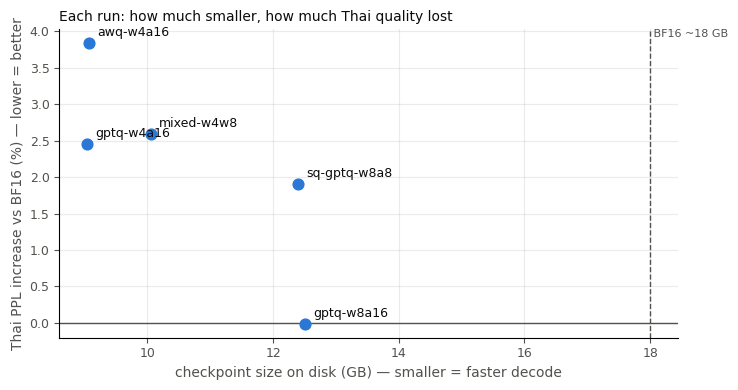

In [ ]:
cmp = pd.read_csv(RESULTS_DIR / 'quantization' / 'compare.csv')
latest = cmp.groupby('variant').tail(1).reset_index(drop=True)
cols = ['variant', 'size_gb', 'mtp', 'dppl_trace_%', 'top1_trace_%', 'dppl_th_%', 'top1_th_%',
        'dppl_en_%', 'top1_en_%', 'probe_rtn_err_%', 'probe_out_err_%', 'quant_min', 'hub']
display(latest[[c for c in cols if c in latest.columns]])
fig = ex.plot_compare(cmp); plt.show()

## ส่งมอบให้ serving
สร้าง `results/handoff/HANDOFF.md` ซึ่งมีลำดับสูตรที่ควร benchmark (W8A8 ก่อน), ตารางคุณภาพ (รวม trace), ชื่อ repo, คำสั่ง `vllm serve` ที่ตรงสัญญาของ grader (tool parser `qwen3_coder`, usage ใน stream, max-model-len 49152) ทั้งแบบปิดและเปิด MTP และ checklist ที่ต้อง A/B บน Validation พร้อม push model card เป็น README ของแต่ละ repo

serving ใช้ `serve/serve_grader.sh` เปิด server และ `python -m gm.loadtest` (หรือ `serve/sweep.sh`) จำลอง grader บน VM เพื่อเลือก MTP / max-num-seqs / clock ก่อนส่ง Validation

เกณฑ์เริ่มต้น: PPL เพิ่มไม่เกิน 5% และต้องมีหัว MTP (ปรับได้เมื่อกรรมการประกาศเกณฑ์จริง)

✅ ควรเห็น: รายการ "Benchmark these, in this order" และตารางคุณภาพ ช่อง `loads in vLLM` จะเป็น `not yet` ซึ่งปกติ เพราะ serving จะเป็นคนโหลดใน vLLM ก่อน

**สิ่งที่ต้องทำต่อ:** (1) ส่งลิงก์ `HANDOFF.md` บน Drive ให้เพื่อนที่ทำ serving (2) เพิ่มเพื่อนเป็นสมาชิกของ repo private บน Hugging Face หรือย้าย repo ไปไว้ใน organization ของทีม

In [ ]:
cmd = [sys.executable, '-m', 'gm.handoff', '--results-dir', str(RESULTS_DIR), '--max-ppl-increase', '5']
if PUSH and HF_USER:
    cmd.append('--push-cards')
run_live(cmd)
display(Markdown((RESULTS_DIR / 'handoff' / 'HANDOFF.md').read_text()))